Part 1: Missing Data and Imputation (8 pts)

1. [8 pts] Notebook review: 

a. One of the cells in the notebook errors out. Why?  
ANSWER:
One of the cells in the notebook errors out because there is missing data not because the code is incorrect. For example, in the code error it says that "Input X contains NaN" presenting that there are missing values for predictors. The function LinearRegression() cannot fit the model when the predictor data contains missing values. 

b. [1 pt] What does the correlation plot tell us?  
ANSWER:
The heatmap for correlation presents sysBP and age has the highest correlation, while cigsPerDay and totchol has the weakest correlation. It also appears that the correlations between cigsPerDay and the other variables are generally negative.

c. [2 pts] As part of this notebook, we delete 80% of the values of sysBP, so we can simulate the impact of missing data and imputation. Based on how we did the deletion, does this make the missing sysBP data MAR, MNAR, or MCAR? Explain your choice.  
ANSWER:
Based on the deletion, the missing sysBP data is MCAR, since it was removed randomly without using any of the other variables to decide what is removed from the dataset. 

d. [2 pts] In Approach #2, we fit a second model with significantly fewer data points from our baseline (831 vs 4143) and plot the coefficient values for each model. What does this plot tell you about the impact of removing sysBP on coefficient estimates?   
ANSWER:
- The coefficient estimates looks like decreased for cigsPerDay and sysBP from Model 1 to Model 2, while increased for age and BMI from Model 1 to Model 2. So, removing 80% of the sysBP values caused on coefficient estimates has decreased the amount of observations we can estimate the coefficients meaning that may be why we're seeing a variety in coefficient estimates. 
- The plot also shows how there is a wider confidence interval for Model 2 compared to Model 1. 

e. [2 pts] In Approach #3, we used mean imputation to impute missing values for sysBP. Why might I have chosen to do this using the mean value calculated from the dataset with 80% of the values missing vs the entire dataset we started with at the beginning?
ANSWER:
You chose to use the mean value calculated from the dataset with 80% of the values missing vs the entire dataset we started with at the beginning because the missing values are unknown, so we calculate the mean from the values that are available and replace the missing values. 

Part 2: Regularization (15 pts) 

1. [3pts] Fit the following two models using OLS: 1) Predict mpg using all of the numeric features. 2) Predict mpg using horsepower, weight, and year only. You do not need to use a train/test split r cross validation for this part of the exercise. You DO need to use StandardScaler on the variables. 

a. Output the coefficients for both models in a table. We will be adding to this table in subsequent parts of this question.    

In [4]:
#importing/loading data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

auto = pd.read_csv("../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]

X = auto[num]
y = auto["mpg"]

SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
alphas = np.logspace(-3, 3, 100)
auto.shape

(392, 9)

In [11]:
#model 1
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [7]:
#dataframe
pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model[-1].coef_
})

,Feature,Coefficient
0,displacement,0.290715
1,horsepower,0.039216
2,weight,-5.831154
3,acceleration,0.248872
4,year,2.774417


In [ ]:
#model 2
X_small = auto[["horsepower", "weight", "year"]]

model_small = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model_small.fit(X_small, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['horsepower','weight','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [10]:
#data frame
pd.DataFrame({
    "Feature": X_small.columns,
    "Coefficient": model_small[-1].coef_
})

,Feature,Coefficient
0,horsepower,-0.192201
1,weight,-5.469742
2,year,2.754512


In [13]:
#comparing coefficients from model 1 vs model 2
comparison = pd.DataFrame({
    "Model 1 (5 predictors)": pd.Series(model[-1].coef_, index=X.columns),

    "Model 2 (3 predictors)": pd.Series(model_small[-1].coef_, index=X_small.columns)
})

comparison.round(5)

,Model 1 (5 predictors),Model 2 (3 predictors)
acceleration,0.24887,NaN
displacement,0.29072,NaN
horsepower,0.03922,-0.19220
weight,-5.83115,-5.46974
year,2.77442,2.75451


b. Why is standardization required for ridge and lasso regression, when for OLS it changed only how we interpret the coefficients, but not the fit of the model?
Ridge and Lasso use standardization because both methods penalize the coefficient size but not affect the predictions. While OLS minimizes the prediction error but does not affect the coefficient size. So, standardization affects the coefficients in OLS, but does not affect the model's predictions.

2. [4pts] Ridge regression 

a. Use RidgeCV(alphas=alphas, cv=cv) in a pipeline with StandardScaler() to fit a ridge model.  

In [14]:
#ridge model with standardScaler()
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=cv)
)

ridge_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


b. Report the penalty (.alpha_) chosen by the ridge regression model and add the coefficients 
to the table you created in Q1.  

In [24]:
#penalty
ridge_model[-1].alpha_

np.float64(1.232846739442066)

In [18]:
#ridge coefficients with old table
comparison["Ridge"] = pd.Series(
    ridge_model[-1].coef_,
    index=X.columns
)

comparison.round(5)

,Model 1 (5 predictors),Model 2 (3 predictors),Ridge
acceleration,0.24887,NaN,0.20113
displacement,0.29072,NaN,0.14726
horsepower,0.03922,-0.19220,-0.04435
weight,-5.83115,-5.46974,-5.63395
year,2.77442,2.75451,2.75273


c. Are any of the ridge coefficients exactly zero? Compare the ridge coefficients to the full OLS model from Q1. Which coefficients changed the most?

ANSWER:
None of the ridge coefficients are exactly zero. It looks like weight's coefficient changed the most compared to the other categories. 

3. [4pts] Lasso regression  

a. Use LassoCV(alphas=alphas, cv=cv) in a pipeline with StandardScaler() to fit a lasso model.  

In [20]:
#lasso model with standardscaler()
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alphas, cv=cv)
)

lasso_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


b. Report the penalty (.alpha_) chosen by the lasso regression model and add the coefficients to the table you created in Q1. Which features did the lasso model drop? (e.g. the coefficient went to zero.) 

ANSWER:
The lasso model drops displacement ans horsepower. 

In [ ]:
#penalty
lasso_model[-1].alpha_

In [23]:
#lasso coefficients with old table
comparison["Lasso"] = pd.Series(
    lasso_model[-1].coef_,
    index=X.columns
)

comparison.round(5)

,Model 1 (5 predictors),Model 2 (3 predictors),Ridge,Lasso
acceleration,0.24887,NaN,0.20113,0.15415
displacement,0.29072,NaN,0.14726,-0.00000
horsepower,0.03922,-0.19220,-0.04435,-0.00000
weight,-5.83115,-5.46974,-5.63395,-5.53236
year,2.77442,2.75451,2.75273,2.72066


c. In general, for a Lasso model that chooses three coefficients, why might we trust this more than those chosen by a Forward/Backward selection with k=3? What limits might the Lasso regression have? 

ANSWER: 
We trust lasso more than forward/backwards selections because lasso uses regularization and validations to pick predictors while forward/backward selection picks predictors to be added or removed. Although lasso regression does have limits such as its selection can be bias based on the alpha number and sensitive to predictos when highly correlated. 

4. [4pts] ElasticNet 

a. Use `ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)` in a pipeline with `StandardScaler()`. This lets cross-validation choose both the penalty strength and the ridge/lasso mix.  

In [25]:
#ElasticNet model with standardsclar()
elastic_model = make_pipeline(
    StandardScaler(),
    ElasticNetCV(
        alphas=alphas,
        l1_ratio=[0.1, 0.5, 0.9, 1],
        cv=cv
    )
)

elastic_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('elasticnetcv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


b. Report the chosen `alpha_`, the chosen `l1_ratio_`, and the coefficients. Add the coefficients to the table you created in Q1. What does the chosen ` l1_ratio_` tell you? 

ANSWER:
l1_ratio_` tells us that the model used lasso regularization with no ridge. 

In [29]:
#alpha
elastic_model[-1].alpha_

np.float64(0.049770235643321115)

In [30]:
#l1_ratio for ElasticNet
elastic_model[-1].l1_ratio_

np.float64(1.0)

In [31]:
#ElasticNet coefficients with old table
comparison["ElasticNet"] = pd.Series(
    elastic_model[-1].coef_,
    index=X.columns
)

comparison.round(5)

,Model 1 (5 predictors),Model 2 (3 predictors),Ridge,Lasso,ElasticNet
acceleration,0.24887,NaN,0.20113,0.15415,0.15415
displacement,0.29072,NaN,0.14726,-0.00000,-0.00000
horsepower,0.03922,-0.19220,-0.04435,-0.00000,-0.00000
weight,-5.83115,-5.46974,-5.63395,-5.53236,-5.53236
year,2.77442,2.75451,2.75273,2.72066,2.72066


c. Looking at all of the approaches in this Part of the lab, which features do the different methods agree are important? 

ANSWER:
The features that the different methods agree are important is weight and year. Year has the strongest negative coefficient, while year has the strongest positive coefficient. 

AI Usage in part 2:
I used GenAI to help explain concepts, such as lasso and elasticnet regression, by suggesting beginner-friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and I tested the code in Jupyter Notebook. 

Part 3: Logistic Regression (15 pts)

1. [3 pts] Baselines 

In [34]:
#importing/dataset load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

fram = pd.read_csv("../data/framingham.csv").dropna()

y = fram["TenYearCHD"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Preprocess by scaling numeric variables using StandardScaler
# Keep the binary male variable unchanged
# For Model A, use age as the numeric variable

numeric = ["age"]

preprocess = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), numeric),
])

a. What fraction of the patients developed CHD within 10 years?  

ANSWER: 15.23%

In [ ]:
#mean
y.mean()

#fraction of patients developed CHD = 15.23%

np.float64(0.15226899945325315)

b. Suppose a “model” predicts no CHD for every patient. What is its accuracy?  

ANSWER:
84.77% accuracy

In [37]:
#cal no CHD for every patient
baseline_accuracy = 1 - y.mean()

baseline_accuracy

np.float64(0.8477310005467469)

c. For the “model” in part b, we compute the same probability for each patient, and it is 
equal to the fraction of patients from part a. What is the log_loss for this “model”?  

ANSWER:
log_loss = 0.42662

In [40]:
#cal fraction of patients who developed CHD
p = y.mean()

#CHD probability for every patient
baseline_prob = np.full(len(y), p)

#cal log loss
baseline_logloss = log_loss(y, baseline_prob)

baseline_logloss

0.4266247901946631

2. [4pts] Fit both models and compute log loss.  

a. Fit Model A and Model B as described above. You do not need to use a holdout set for 
this part, we will use cross-validation shortly.   

In [41]:
#Model A categories
X_A = fram[["male", "age"]]

#Model A
model_A = Pipeline([
    ("preprocess", preprocess),
    ("logistic", LogisticRegression())
])

model_A.fit(X_A, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['male','age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transf

In [42]:
#Model B categories
X_B = fram[["male", "cigsPerDay"]]

#Model B preprocess
preprocess_B = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["cigsPerDay"])
])

#Model B
model_B = Pipeline([
    ("preprocess", preprocess_B),
    ("logistic", LogisticRegression())
])

model_B.fit(X_B, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['male','cigsPerDay']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in 

b. For each model, get the predicted probabilities of CHD using predict_proba (as we did in 
class) and compute the log_loss for each using the sklearn log_loss function.  

In [43]:
#prob of CHD for Model A
prob_A = model_A.predict_proba(X_A)[:, 1]

#log loss for Model A
logloss_A = log_loss(y, prob_A)

logloss_A

0.39419926744392164

In [45]:
#prob of CHD for Model B
prob_B = model_B.predict_proba(X_B)[:, 1]

#log loss for Model B
logloss_B = log_loss(y, prob_B)

logloss_B

0.42220493256182945

c. For Model A, compute the log loss by hand with NumPy. It should match the value from 
sklearn

In [46]:
#Model A log loss
manual_logloss_A = -np.mean(
    y * np.log(prob_A) +
    (1 - y) * np.log(1 - prob_A)
)

manual_logloss_A

np.float64(0.39419926744392164)

3. 8 pts] Now let’s determine which model is better. All of the numbers above are in sample, so we 
need to use cross-validation for this part. 

a. Use `cross_validate` with the `cv` object from the setup and `scoring=["accuracy", 
"neg_log_loss", "roc_auc"]` to evaluate both models. Report the mean and standard deviation 
across the 5 folds for each metric. (Remember that sklearn negates log loss, so flip the 
sign back.) 

In [52]:
#Model A with 5-fold cross-validation
scores_A = cross_validate(
    model_A,
    X_A,
    y,
    cv=cv,
    scoring=["accuracy", "neg_log_loss", "roc_auc"]
)

#results
pd.DataFrame({
    "Mean": [
        scores_A["test_accuracy"].mean(),
        scores_A["test_neg_log_loss"].mean(),
        scores_A["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        scores_A["test_accuracy"].std(),
        scores_A["test_neg_log_loss"].std(),
        scores_A["test_roc_auc"].std()
    ]
}, index=["Accuracy", "Negative Log Loss", "ROC AUC"]).round(5)

,Mean,Standard Deviation
Accuracy,0.84800,0.00101
Negative Log Loss,-0.39526,0.01336
ROC AUC,0.70129,0.03963


In [54]:
#Model B with 5-fold cross-validation
scores_B = cross_validate(
    model_B,
    X_B,
    y,
    cv=cv,
    scoring=["accuracy", "neg_log_loss", "roc_auc"]
)

#results
pd.DataFrame({
    "Mean": [
        scores_B["test_accuracy"].mean(),
        scores_B["test_neg_log_loss"].mean(),
        scores_B["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        scores_B["test_accuracy"].std(),
        scores_B["test_neg_log_loss"].std(),
        scores_B["test_roc_auc"].std()
    ]
}, index=["Accuracy", "Negative Log Loss", "ROC AUC"]).round(5)

,Mean,Standard Deviation
Accuracy,0.84773,0.00061
Negative Log Loss,-0.42335,0.00226
ROC AUC,0.56447,0.03186


b. Compare the CV accuracy of the two models with the baseline accuracy from Q1(b). Is accuracy a useful metric for choosing between these models? Why or why not? 

ANSWER:
- Q1(b)= 84.77% accuracy (for baseline)
- Model A = 84.80% accuracy
- Model B = 84.77% accuracy
It shows that Model A did slightly better than the other two model, while Model B and Q1(b) have the same exact accuracy precentage. This also shpws that accuracy is not a useful metric for choosing between these models since the accuracy percentages are so close to each other.

c. Use `cross_val_predict` with `method="predict_proba"` to get out-of-fold predicted 
probabilities for each model. Plot the confusion matrices for both models at thresholds of 
0.5 and 0.2. What do you observe? 

ANSWER:
- Model A and B at threshold 0.5 had poor results when identifying patients who develop CHD
- Model A at threshold 0.2 has good results when identifying patients who develop CHD, but also did not correctly marked patients who did had CHD, while Model B did more accurately in marking the correct patients who did had CHD


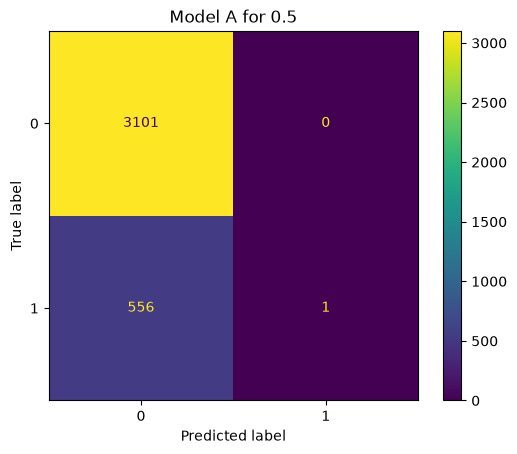

In [59]:
#Model A cross-validate
prob_cv_A = cross_val_predict(
    model_A,
    X_A,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

#probability to predictions with 0.5
pred_A_05 = (prob_cv_A >= 0.5).astype(int)

#plot
ConfusionMatrixDisplay.from_predictions(y, pred_A_05)
plt.title("Model A for 0.5")
plt.show()

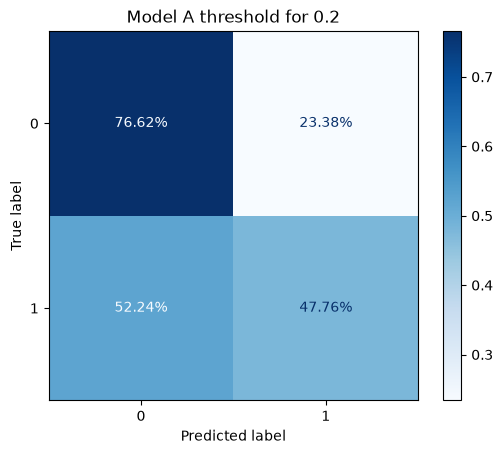

In [69]:
#Model A threshold of 0.2
pred_A_02 = (prob_cv_A >= 0.2).astype(int)

#plot
ConfusionMatrixDisplay.from_predictions(
    y,
    pred_A_02,
    normalize="true",
    cmap="Blues",
    values_format=".2%"
)

plt.title("Model A threshold for 0.2")
plt.show()

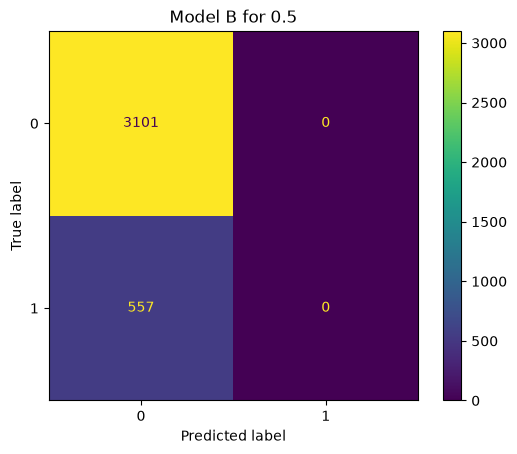

In [61]:
#Model B cross-validate
prob_cv_B = cross_val_predict(
    model_B,
    X_B,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

#probability to predictions with 0.5
pred_B_05 = (prob_cv_B >= 0.5).astype(int)

#plot
ConfusionMatrixDisplay.from_predictions(y, pred_B_05)
plt.title("Model B for 0.5")
plt.show()

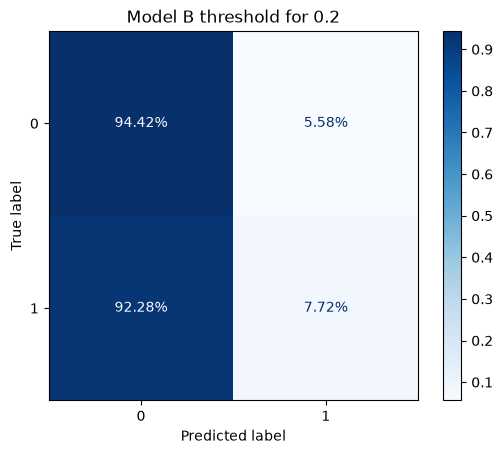

In [67]:
#Model B threshold of 0.2
pred_B_02 = (prob_cv_B >= 0.2).astype(int)

#plot
ConfusionMatrixDisplay.from_predictions(
    y,
    pred_B_02,
    normalize="true",
    cmap="Blues",
    values_format=".2%"
)

plt.title("Model B threshold for 0.2")
plt.show()

d. Based on the log_loss, roc_auc, and confusion matrices, which model would you choose 
and why? Relate your answer to the log loss rate for the “model” in Q1

ANSWER:
The model I would chose is Model A because it has the lowest log loss and highest ROC AUC compared to the other two models. Model A has mentioned before gives a high percentage of false positives in which Model A at threshold 0.2 gave the highest accurancy in identifying CHD.

AI Usage in part 3:
I used GenAI to help explain concepts, such as log loss and logistic regression, by suggesting beginner-friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and I tested the code in Jupyter Notebook.